<a href="https://colab.research.google.com/github/eaedk/Machine-Learning-Tutorials-Updated/blob/main/03_computer_vision/09_keypoints_pose_app.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🐅 Application · Keypoints & pose estimation: from human skeletons to tigers

**Pose estimation** finds the position of **keypoints**: the joints of a body (shoulders, elbows, knees…), the
corners of a face, the paws and tail of an animal. Connect them and you get a **skeleton** that describes posture and
movement.

Applications are everywhere: sports analytics (a sprinter's stride, a bowler's arm angle), physiotherapy and fitness
coaching apps, fall detection for elderly people, sign-language recognition, animation and video games… and
**animal behaviour**: zoologists track the gait of tigers, mice or horses to study health and welfare without
touching the animals.

**A short history**
- **2010 · Microsoft Kinect** tracks the skeleton of players in real time with a depth camera.
- **2017 · OpenPose** (Carnegie Mellon University): real-time multi-person 2D pose from a normal camera.
- **2018 · DeepLabCut** brings pose estimation to neuroscience labs with a few hundred labelled animal images.
- **Today:** one-stage models like **YOLO26-pose** detect each person/animal *and* its keypoints in a single pass.

**Your mission:** analyse human poses with a pre-trained model (and build a tiny exercise coach), then fine-tune a
model to find the 12 keypoints of **tigers**.

In [1]:
# ⚙️ Setup: run me first! Finds the course toolkit `mlquest` (Windows, macOS, Linux and Colab).
import os, sys, subprocess, pathlib
if "google.colab" in sys.modules:  # on Colab: grab the repo (once) and the few missing packages
    if not pathlib.Path("/content/Machine-Learning-Tutorials-Updated").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/eaedk/Machine-Learning-Tutorials-Updated", "/content/Machine-Learning-Tutorials-Updated"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)
    os.chdir("/content/Machine-Learning-Tutorials-Updated")
ROOT = pathlib.Path.cwd()
while not (ROOT / "mlquest").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from mlquest import *  # paths, seed_everything, get_device, quest/checkpoint, Leaderboard...
set_style()
SEED = seed_everything(42)

In [2]:
import os, shutil, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

os.environ["YOLO_VERBOSE"] = "False"          # quiet logs ("True" to watch every training step)
from ultralytics import YOLO
from ultralytics.utils import ASSETS, YAML
from ultralytics.utils.checks import check_yaml

DEVICE = get_device()
YOLO_DATA = DATA_DIR / "yolo_datasets"
WEIGHTS = DATA_DIR / "weights"
WEIGHTS.mkdir(exist_ok=True)


def yolo_dataset(yaml_name: str) -> Path:
    """Download an Ultralytics dataset into data/yolo_datasets/ and return a YAML pointing to it."""
    cfg = YAML.load(check_yaml(f"{yaml_name}.yaml"))
    folder = YOLO_DATA / Path(cfg["path"]).name
    if not folder.exists():
        url = cfg["download"]
        stem = Path(url).stem
        archive = download(url, YOLO_DATA / Path(url).name)
        tmp = extract(archive, YOLO_DATA / f"_tmp_{stem}")
        inner = tmp / stem if (tmp / stem).is_dir() else tmp
        shutil.move(str(inner), str(folder))
        shutil.rmtree(tmp, ignore_errors=True)
        archive.unlink()
    cfg["path"] = str(folder)
    cfg.pop("download", None)
    out = YOLO_DATA / f"{yaml_name}.yaml"
    YAML.save(out, cfg)
    return out

quest("From human skeletons to tigers", chapter="Track 3 · Computer vision · Keypoints", xp=250)

⚙️  Using device: mps  (Apple Silicon GPU (Metal))
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
🗺️  QUEST · From human skeletons to tigers
   Track 3 · Computer vision · Keypoints
   Reward: up to 250 XP
   You are: 🥚 Curious Rookie   ░░░░░░░░░░░░░░░░░░░░░░░░ 0/100 XP
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


## 1. Human pose with a pre-trained model 🧍

COCO defines **17 body keypoints** per person: nose, eyes, ears, shoulders, elbows, wrists, hips, knees, ankles.
YOLO26n-pose detects every person and returns, for each one, 17 `(x, y)` positions with a confidence.

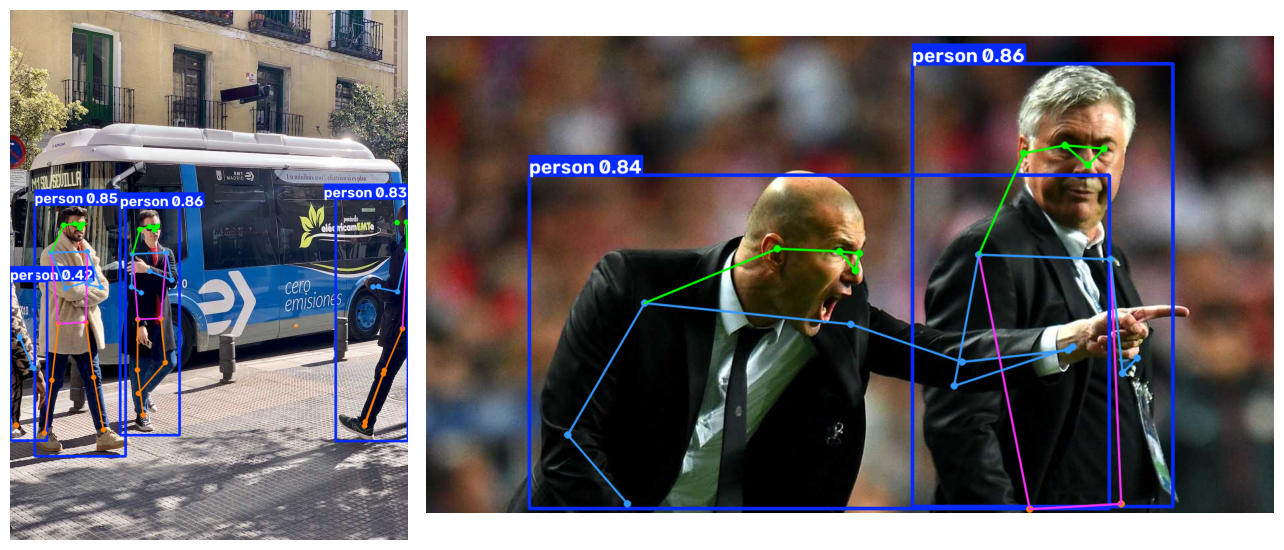

keypoints tensor: (2, 17, 2) → (people, 17 keypoints, x/y)


,nose,left_eye,right_eye,left_ear,right_ear,left_shoulder,right_shoulder,left_elbow,right_elbow,left_wrist,right_wrist,left_hip,right_hip,left_knee,right_knee,left_ankle,right_ankle
x,1000.0,1023.0,965.0,1044.0,902.0,1034.0,834.0,1051.0,797.0,1073.0,976.0,1049.0,911.0,1076.0,932.0,1043.0,927.0
y,194.0,169.0,164.0,187.0,176.0,337.0,329.0,508.0,528.0,485.0,469.0,705.0,714.0,718.0,720.0,711.0,701.0


In [3]:
KPT = ["nose", "left_eye", "right_eye", "left_ear", "right_ear", "left_shoulder", "right_shoulder", "left_elbow",
       "right_elbow", "left_wrist", "right_wrist", "left_hip", "right_hip", "left_knee", "right_knee",
       "left_ankle", "right_ankle"]
pose = YOLO(str(WEIGHTS / "yolo26n-pose.pt"))
results = pose.predict([ASSETS / "bus.jpg", ASSETS / "zidane.jpg"], conf=0.4, device=DEVICE)
fig, axes = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [0.75, 1.6]})
for ax, r in zip(axes, results):
    ax.imshow(r.plot()[..., ::-1]); ax.axis("off")
plt.tight_layout(); plt.show()

r = results[1]
print("keypoints tensor:", tuple(r.keypoints.xy.shape), "→ (people, 17 keypoints, x/y)")
pd.DataFrame(r.keypoints.xy[0].cpu().numpy().round(0), index=KPT, columns=["x", "y"]).T

## 2. A tiny exercise coach 🏋️

Keypoints become **measurements**. The angle at the elbow, formed by shoulder → elbow → wrist, tells if an arm is
straight (≈180°) or bent. Fitness apps count push-ups or curls exactly like this, frame after frame.

In [4]:
def joint_angle(a, b, c):
    """Angle (degrees) at point b formed by the segments b→a and b→c."""
    ba, bc = np.asarray(a) - np.asarray(b), np.asarray(c) - np.asarray(b)
    cos = np.dot(ba, bc) / (np.linalg.norm(ba) * np.linalg.norm(bc) + 1e-9)
    return float(np.degrees(np.arccos(np.clip(cos, -1, 1))))

rows = []
for res in results:
    for p, (xy, conf) in enumerate(zip(res.keypoints.xy.cpu().numpy(), res.keypoints.conf.cpu().numpy())):
        k = {name: xy[i] for i, name in enumerate(KPT)}
        ok = lambda *names: all(conf[KPT.index(n)] > 0.5 for n in names)
        rows.append({
            "image": Path(res.path).name, "person": p,
            "left_elbow_°": round(joint_angle(k["left_shoulder"], k["left_elbow"], k["left_wrist"])) if ok("left_shoulder", "left_elbow", "left_wrist") else None,
            "right_elbow_°": round(joint_angle(k["right_shoulder"], k["right_elbow"], k["right_wrist"])) if ok("right_shoulder", "right_elbow", "right_wrist") else None,
            "left_knee_°": round(joint_angle(k["left_hip"], k["left_knee"], k["left_ankle"])) if ok("left_hip", "left_knee", "left_ankle") else None,
        })
angles = pd.DataFrame(rows)
angles["arms"] = np.where(angles[["left_elbow_°", "right_elbow_°"]].min(axis=1) < 120, "bent 💪", "straight")
angles

,image,person,left_elbow_°,right_elbow_°,left_knee_°,arms
0,bus.jpg,0,56.0,117.0,132.0,bent 💪
1,bus.jpg,1,57.0,95.0,178.0,bent 💪
2,bus.jpg,2,92.0,NaN,NaN,bent 💪
3,bus.jpg,3,NaN,NaN,NaN,straight
4,zidane.jpg,0,NaN,61.0,NaN,bent 💪
5,zidane.jpg,1,155.0,NaN,NaN,straight


(Missing values = the joint was not visible with enough confidence: a good coach doesn't guess!)

In [5]:
checkpoint("pose/human", xp=50)

✅ Checkpoint · pose/human (+50 XP)
   ████████████░░░░░░░░░░░░ 50/100 XP


## 3. How is pose scored? OKS 📏

For boxes we used IoU. For keypoints, competitions (COCO, and most pose challenges) use the **Object Keypoint
Similarity**:

$$\text{OKS} = \frac{1}{K}\sum_i \exp\left(-\frac{d_i^2}{2\,s^2\,k_i^2}\right)$$

- $d_i$: distance between the predicted and true keypoint $i$,
- $s$: the object scale (bigger animal → more tolerance in pixels),
- $k_i$: a per-keypoint tolerance (an eye must be precise; a hip is harder to locate, so it gets more slack).

OKS = 1 is perfect, 0 is far off. Then, like for boxes: precision/recall at OKS thresholds → **pose mAP50** and
**mAP50-95**.

## 4. Fine-tune on tigers 🐅

The *Tiger-pose* dataset (Ultralytics) has 263 images of tigers with **12 keypoints**: nose, head, withers, tail base
and the four legs (hock/wrist and paw). We start from the human pose model: its backbone already knows a lot about
bodies and limbs; the keypoint head is re-created for 12 points.

In [6]:
tiger_yaml = yolo_dataset("tiger-pose")          # ~52 MB
cfg = YAML.load(tiger_yaml)
TIGER_KPT = cfg["kpt_names"][0]
print("keypoints:", ", ".join(TIGER_KPT))
for split in ["train", "val"]:
    print(f"{split}: {len(list((YOLO_DATA / 'tiger-pose' / 'images' / split).glob('*')))} images")

keypoints: nose, head, withers, tail_base, right_hind_hock, right_hind_paw, left_hind_paw, left_hind_hock, right_front_wrist, right_front_paw, left_front_wrist, left_front_paw
train: 210 images
val: 53 images


In [7]:
model = YOLO(str(WEIGHTS / "yolo26n-pose.pt"))
t0 = time.time()
metrics = model.train(data=str(tiger_yaml), epochs=30, imgsz=416, batch=16, device=DEVICE, workers=NUM_WORKERS,
                      project=str(RUNS_DIR / "pose"), name="tiger", exist_ok=True,
                      plots=False, deterministic=False, seed=SEED)
print(f"⏱️  {(time.time() - t0) / 60:.1f} min · box mAP50 = {metrics.box.map50:.3f} · "
      f"pose mAP50 = {metrics.pose.map50:.3f} · pose mAP50-95 = {metrics.pose.map:.3f}")
lb = Leaderboard("tiger_pose", metric="val_pose_mAP50-95")
lb.add("YOLO26n-pose · 30 epochs · 416px", metrics.pose.map, pose_mAP50=round(metrics.pose.map50, 3))

⏱️  4.7 min · box mAP50 = 0.995 · pose mAP50 = 0.995 · pose mAP50-95 = 0.377
📋 YOLO26n-pose · 30 epochs · 416px: val_pose_mAP50-95 = 0.37659


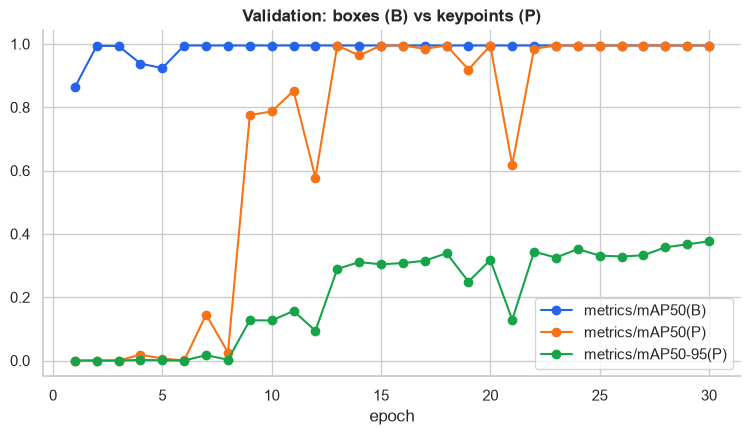

✅ Checkpoint · pose/tiger (+60 XP)
🎉 LEVEL UP! You are now 🐣 Data Explorer
   █░░░░░░░░░░░░░░░░░░░░░░░ 110/300 XP


In [8]:
curves = pd.read_csv(Path(model.trainer.save_dir) / "results.csv")
curves.columns = curves.columns.str.strip()
curves.plot(x="epoch", y=["metrics/mAP50(B)", "metrics/mAP50(P)", "metrics/mAP50-95(P)"], marker="o",
            title="Validation: boxes (B) vs keypoints (P)"); plt.show()
checkpoint("pose/tiger", xp=60)

Finding the tiger (box) is easy; placing 12 keypoints precisely (pose mAP50-95) is much harder, especially legs that
cross each other or hide behind the body.

⚠️ Be critical of the near-perfect mAP50: the images are frames from a few videos of the **same tiger in the same
enclosure**, so validation frames look a lot like training frames. On a new tiger in a new place, expect lower scores.
For a real project you would split by video (remember the group trap of the playbook).

## 5. Tigers in motion 🎞️

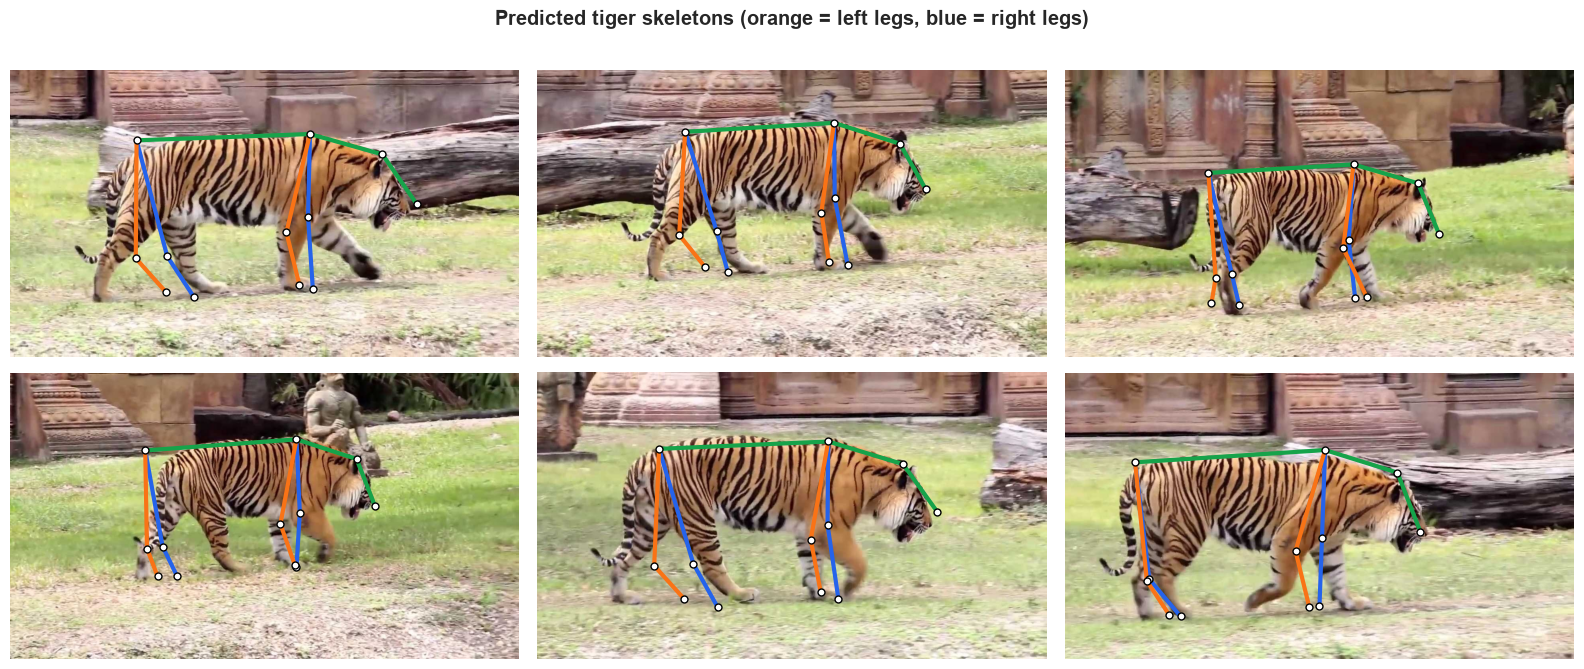

In [9]:
best = YOLO(str(Path(model.trainer.save_dir) / "weights" / "best.pt"))
val_imgs = sorted((YOLO_DATA / "tiger-pose" / "images" / "val").glob("*"))
picks = [val_imgs[i] for i in np.linspace(0, len(val_imgs) - 1, 6).astype(int)]
res = best.predict(picks, imgsz=416, conf=0.4, device=DEVICE)

# The dataset defines no skeleton for tigers, so we draw our own bones between keypoints
BONES = [("nose", "head"), ("head", "withers"), ("withers", "tail_base"),
         ("withers", "right_front_wrist"), ("right_front_wrist", "right_front_paw"),
         ("withers", "left_front_wrist"), ("left_front_wrist", "left_front_paw"),
         ("tail_base", "right_hind_hock"), ("right_hind_hock", "right_hind_paw"),
         ("tail_base", "left_hind_hock"), ("left_hind_hock", "left_hind_paw")]
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, r in zip(axes.ravel(), res):
    ax.imshow(r.orig_img[..., ::-1]); ax.axis("off")
    if r.keypoints is None or len(r.keypoints.xy) == 0:
        continue
    k = dict(zip(TIGER_KPT, r.keypoints.xy[0].cpu().numpy()))
    for a, b in BONES:
        color = "#f97316" if "left" in b else "#2563eb" if "right" in b else "#16a34a"
        ax.plot([k[a][0], k[b][0]], [k[a][1], k[b][1]], color=color, lw=3)
    xy = np.array(list(k.values()))
    ax.scatter(xy[:, 0], xy[:, 1], s=25, c="white", edgecolors="black", zorder=3)
plt.suptitle("Predicted tiger skeletons (orange = left legs, blue = right legs)", fontweight="bold")
plt.tight_layout(); plt.show()

### From keypoints to biology: the stride
With keypoints on every frame of a video, a biologist can measure the **stride** (distance between front and hind paws
relative to body length) and spot a limping animal. Here on single images:

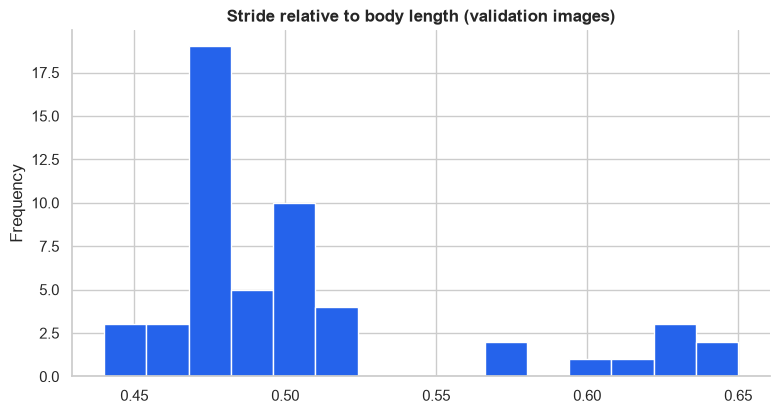

,body_length_px,stride / body
count,53.00,53.00
mean,683.40,0.51
std,58.07,0.05
min,567.00,0.44
25%,649.00,0.48
50%,697.00,0.49
75%,735.00,0.50
max,764.00,0.65


In [10]:
rows = []
for r in best.predict(val_imgs, imgsz=416, conf=0.4, device=DEVICE):
    if r.keypoints is None or len(r.keypoints.xy) == 0:
        continue
    k = dict(zip(TIGER_KPT, r.keypoints.xy[0].cpu().numpy()))
    body = np.linalg.norm(k["nose"] - k["tail_base"])
    stride = np.linalg.norm(k["left_front_paw"] - k["left_hind_paw"])
    rows.append({"image": Path(r.path).stem, "body_length_px": round(float(body)), "stride / body": round(float(stride / (body + 1e-9)), 2)})
gait = pd.DataFrame(rows)
gait["stride / body"].plot.hist(bins=15, title="Stride relative to body length (validation images)"); plt.show()
gait.describe().round(2)

## 🏁 Mission accomplished

You extracted human skeletons, turned keypoints into joint angles, understood OKS and trained a tiger pose model.

### 🚀 Your turn (bonus XP)
1. Count push-ups in a video: run `pose.predict` on each frame and count the elbow angle crossing 90° → 160°.
2. Train the tiger model longer (80 epochs) or at `imgsz=640`. Which keypoints improve the most?
3. Try the bigger `dog-pose` dataset (24 keypoints, ~8 000 images) with `fraction=0.2` to stay fast.
4. Use `pose.track(source=video)` to follow each person's skeleton over time with a stable ID.

In [11]:
checkpoint("pose/complete", xp=140)
badge("Motion Tracker", "🐅")
progress()

✅ Checkpoint · pose/complete (+140 XP)
   ██████████████████░░░░░░ 250/300 XP
╔═══════════════════════════════════╗
║ 🐅  BADGE UNLOCKED: Motion Tracker ║
╚═══════════════════════════════════╝
🐣 Data Explorer
██████████████████░░░░░░ 250/300 XP
Checkpoints unlocked: 3
Badges: 🐅 Motion Tracker
